# Predicting the electrical output of a combined cycle power plant

**Goal:** estimate the full-load net electrical output (PE, MW) of a combined cycle gas and steam power plant from four hourly ambient measurements, and explain which conditions drive it.

**Data:** 9,568 hourly observations (2006–2011) from the UCI *Combined Cycle Power Plant* dataset (Tüfekci, 2014), licensed CC BY 4.0.

| Variable | Meaning | Unit |
|---|---|---|
| `AT` | Ambient temperature | °C |
| `V` | Exhaust vacuum | cm Hg |
| `AP` | Ambient pressure | mbar |
| `RH` | Relative humidity | % |
| `PE` | Net electrical output (**target**) | MW |

**Workflow:** exploratory analysis → data cleaning → statistical baseline (OLS) → regularised and non-linear models → cross-validation → model explanation (SHAP) → error analysis.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import statsmodels.api as sm
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

SEED = 42
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

BLUE, ORANGE, GREY, RED = "#2a78d6", "#eb6834", "#59636e", "#e34948"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", facecolor="white")

## 1. Data and exploratory analysis

In [2]:
df = pd.read_csv("../data/ccpp.csv")
print(df.shape)
df.describe().T.round(2)

(9568, 5)


,count,mean,std,min,25%,50%,75%,max
AT,9568.0,19.65,7.45,1.81,13.51,20.34,25.72,37.11
V,9568.0,54.31,12.71,25.36,41.74,52.08,66.54,81.56
AP,9568.0,1013.26,5.94,992.89,1009.10,1012.94,1017.26,1033.30
RH,9568.0,73.31,14.60,25.56,63.33,74.97,84.83,100.16
PE,9568.0,454.37,17.07,420.26,439.75,451.55,468.43,495.76


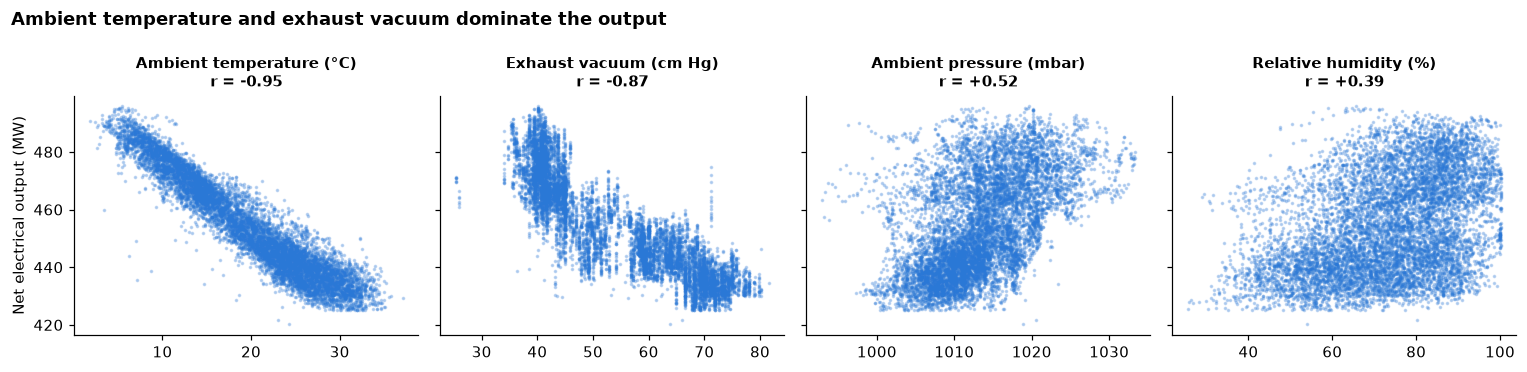

In [3]:
labels = {"AT": "Ambient temperature (°C)", "V": "Exhaust vacuum (cm Hg)",
          "AP": "Ambient pressure (mbar)", "RH": "Relative humidity (%)"}

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, col in zip(axes, labels):
    ax.scatter(df[col], df["PE"], s=2, alpha=0.25, color=BLUE, rasterized=True)
    r = df[col].corr(df["PE"])
    ax.set_title(f"{labels[col]}\nr = {r:+.2f}", fontsize=10)
axes[0].set_ylabel("Net electrical output (MW)")
fig.suptitle("Ambient temperature and exhaust vacuum dominate the output", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "01_feature_relationships")

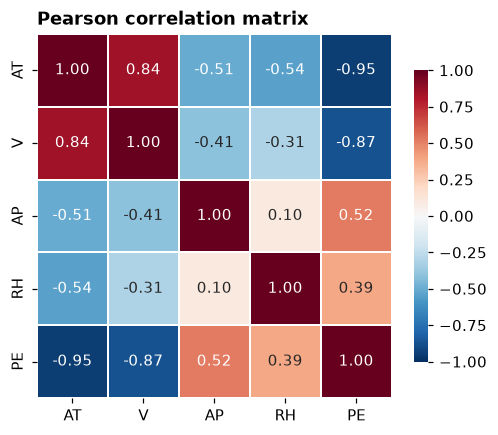

In [4]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(5.2, 4.3))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=1, linecolor="white", cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Pearson correlation matrix", loc="left")
save(fig, "02_correlation_matrix")

**Reading the correlations.** PE falls almost linearly as temperature rises (r = −0.95): warmer, less dense intake air reduces gas turbine output. AT and V are themselves strongly correlated (r = +0.84), which matters for how coefficients are interpreted in a linear model (multicollinearity).

## 2. Cleaning: duplicates and outliers (1.5 × IQR rule)

In [5]:
n0 = len(df)
df = df.drop_duplicates()
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
mask = ~((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).any(axis=1)
clean = df[mask].reset_index(drop=True)
print(f"rows: {n0:,} -> {len(df):,} after duplicates -> {len(clean):,} after IQR filter")

rows: 9,568 -> 9,527 after duplicates -> 9,423 after IQR filter


In [6]:
X = clean[["AT", "V", "AP", "RH"]]
y = clean["PE"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(X_train.shape, X_test.shape)

(7538, 4) (1885, 4)


## 3. Statistical baseline: ordinary least squares

In [7]:
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(ols.summary().tables[1])
print(f"Adjusted R² (train): {ols.rsquared_adj:.4f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        442.5182     11.482     38.539      0.000     420.010     465.027
AT            -1.9789      0.017   -114.712      0.000      -2.013      -1.945
V             -0.2300      0.008    -28.000      0.000      -0.246      -0.214
AP             0.0738      0.011      6.617      0.000       0.052       0.096
RH            -0.1574      0.005    -33.229      0.000      -0.167      -0.148
Adjusted R² (train): 0.9264


**Interpretation.** All four predictors are significant (p < 0.001). Holding the others constant, every additional °C of ambient temperature lowers output by about 2 MW, making it the dominant operational driver.

## 4. Model comparison

In [8]:
models = {
    "Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (CV-tuned)": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 25))),
    "Lasso (CV-tuned)": make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=SEED)),
    "Polynomial (degree 2)": make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()),
    "Neural network (MLP)": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000,
                                                                       early_stopping=True, random_state=SEED)),
    "Random forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    "Gradient boosting": GradientBoostingRegressor(n_estimators=600, learning_rate=0.05, max_depth=4, random_state=SEED),
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
rows, preds = [], {}
for name, model in models.items():
    cvr = cross_validate(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    preds[name] = p
    rows.append({
        "Model": name,
        "CV RMSE (MW)": -cvr["test_score"].mean(),
        "CV RMSE sd": cvr["test_score"].std(),
        "Test RMSE (MW)": mean_squared_error(y_test, p) ** 0.5,
        "Test MAE (MW)": mean_absolute_error(y_test, p),
        "Test R²": r2_score(y_test, p),
    })

results = pd.DataFrame(rows).sort_values("Test RMSE (MW)").reset_index(drop=True)
results.to_csv("../figures/model_results.csv", index=False)
results.round(3)

,Model,CV RMSE (MW),CV RMSE sd,Test RMSE (MW),Test MAE (MW),Test R²
0,Gradient boosting,3.439,0.164,3.210,2.394,0.965
1,Random forest,3.487,0.143,3.227,2.334,0.964
2,Polynomial (degree 2),4.319,0.123,4.085,3.244,0.943
3,Neural network (MLP),4.388,0.134,4.148,3.244,0.941
4,Ridge (CV-tuned),4.607,0.110,4.416,3.556,0.933
5,Linear regression,4.607,0.110,4.416,3.556,0.933
6,Lasso (CV-tuned),4.607,0.109,4.417,3.557,0.933


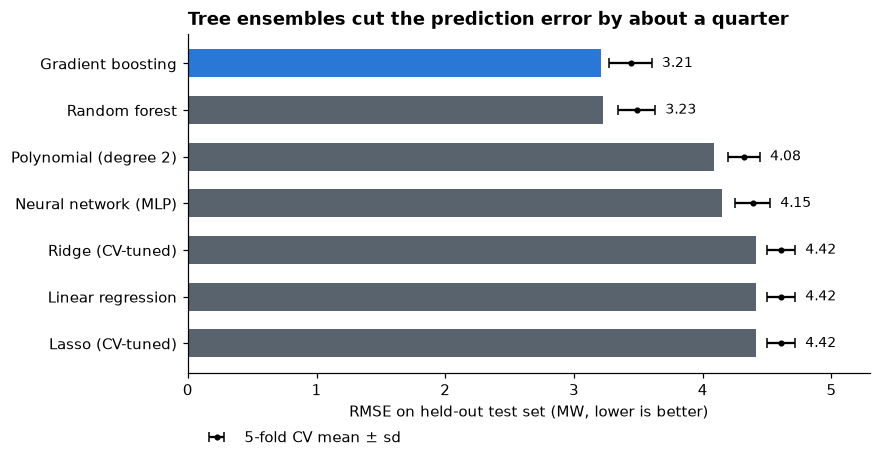

In [9]:
res = results.sort_values("Test RMSE (MW)", ascending=False)
best = results.loc[0, "Model"]
colors = [BLUE if m == best else GREY for m in res["Model"]]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(res["Model"], res["Test RMSE (MW)"], color=colors, height=0.6)
ax.errorbar(res["CV RMSE (MW)"], res["Model"], xerr=res["CV RMSE sd"], fmt="o", color="black", ms=3,
            capsize=3, label="5-fold CV mean ± sd")
for b, v, c, s in zip(bars, res["Test RMSE (MW)"], res["CV RMSE (MW)"], res["CV RMSE sd"]):
    ax.text(max(v, c + s) + 0.08, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlabel("RMSE on held-out test set (MW, lower is better)")
ax.set_xlim(0, res[["Test RMSE (MW)", "CV RMSE (MW)"]].max().max() * 1.15)
ax.set_title("Tree ensembles cut the prediction error by about a quarter", loc="left")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.13), ncol=1)
save(fig, "03_model_comparison")

## 5. Explaining the best model with SHAP

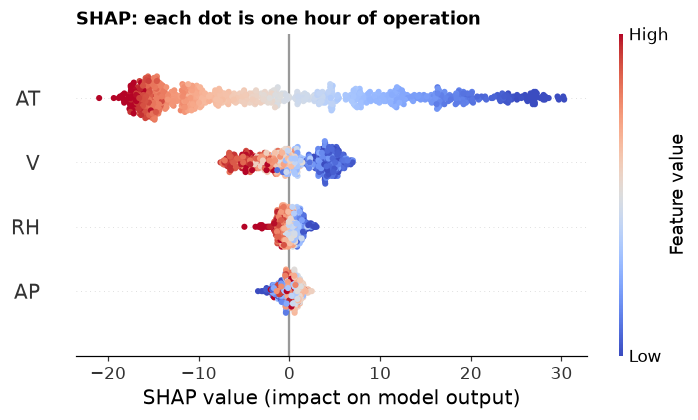

In [10]:
best_model = models[best]
sample = X_test.sample(800, random_state=SEED)
explainer = shap.TreeExplainer(best_model)
sv = explainer(sample)

plt.figure()
shap.plots.beeswarm(sv, show=False, color=plt.get_cmap("coolwarm"))
fig = plt.gcf()
fig.set_size_inches(7.5, 3.8)
plt.title("SHAP: each dot is one hour of operation", loc="left")
save(fig, "04_shap_summary")

In [11]:
imp = pd.Series(np.abs(sv.values).mean(axis=0), index=sample.columns).sort_values(ascending=False)
(imp / imp.sum() * 100).round(1).rename("share of mean |SHAP| (%)")

AT    70.8
V     19.6
RH     5.0
AP     4.6
Name: share of mean |SHAP| (%), dtype: float64

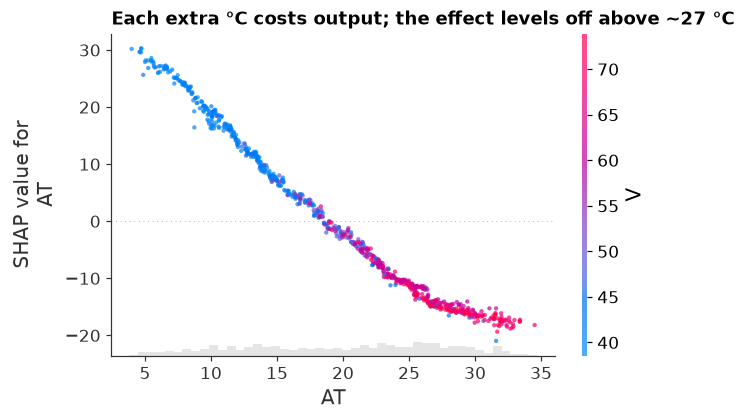

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
shap.plots.scatter(sv[:, "AT"], color=sv[:, "V"], ax=ax, show=False, dot_size=8, alpha=0.7)
ax.set_title("Each extra °C costs output; the effect levels off above ~27 °C", loc="left")
save(fig, "05_shap_temperature")

## 6. Error analysis of the best model

90.8% of test hours are predicted within ±5 MW


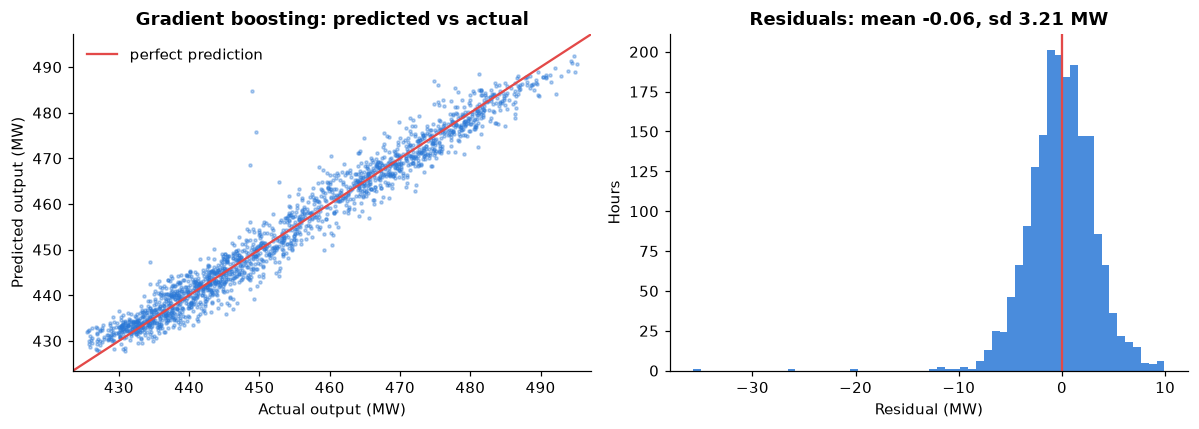

In [13]:
p = preds[best]
resid = y_test - p
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, p, s=4, alpha=0.35, color=BLUE, rasterized=True)
lims = [y_test.min() - 2, y_test.max() + 2]
axes[0].plot(lims, lims, color=RED, lw=1.5, label="perfect prediction")
axes[0].set(xlim=lims, ylim=lims, xlabel="Actual output (MW)", ylabel="Predicted output (MW)",
            title=f"{best}: predicted vs actual")
axes[0].legend(frameon=False)
axes[1].hist(resid, bins=60, color=BLUE, alpha=0.85)
axes[1].axvline(0, color=RED, lw=1.5)
axes[1].set(xlabel="Residual (MW)", ylabel="Hours", title=f"Residuals: mean {resid.mean():+.2f}, sd {resid.std():.2f} MW")
fig.tight_layout()
save(fig, "06_best_model_errors")
print(f"{(resid.abs() < 5).mean():.1%} of test hours are predicted within ±5 MW")

## 7. Conclusions

1. **Ambient temperature is the decisive factor.** It accounts for about 71% of the model's explanatory weight (mean |SHAP|), and in the linear model each extra °C costs about 2 MW. This is directly usable for summer capacity planning.
2. **A linear model is a strong, transparent baseline** (test R² = 0.93, RMSE 4.4 MW), but it misses the curvature in the temperature effect, which flattens above about 27 °C.
3. **Gradient boosting is the most accurate model** (test RMSE 3.2 MW, R² = 0.965). That is about 27% less error than linear regression, and 91% of test hours are predicted within ±5 MW. Five-fold cross-validation confirms that the ranking is stable.
4. **SHAP makes the black-box model auditable.** It recovers the physics (hot air means less output) and shows that temperature and exhaust vacuum act together.

*Limitations:* the data are hourly averages without time ordering, so this is a static model that does not forecast future conditions, and it covers full-load operation only.